In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
sys.path.insert(0, str(Path.cwd().parent / 'python'))
from analysis_common import analytical_src, segment_metrics
from config import AGGREGATE_DIR, AUDIT_DIR, CLEAN_PARQUET, DOCS_DIR, STATS_DIR, VISUALS_DIR, connect
pd.set_option('display.max_columns', 40, 'display.width', 180, 'display.float_format', '{:,.4f}'.format)
con = connect(); src = analytical_src()
kpi = json.loads((AGGREGATE_DIR / 'portfolio_kpis.json').read_text())
fin = json.loads((AGGREGATE_DIR / 'financial_totals.json').read_text())
show = lambda name: display(Image(filename=str(VISUALS_DIR / f'{name}.png')))
csv = lambda name: pd.read_csv(AGGREGATE_DIR / f'{name}.csv')

# 3. Exploratory Analysis
Portfolio, default, interest-rate, time and geographic views (`python/eda.py`).

In [2]:
live = con.execute(f'SELECT SUM(is_charged_off)*1.0/SUM(is_resolved) FROM {src}').fetchone()[0]
assert abs(live - kpi['default_rate']) < 1e-12
print(f"Default rate {live:.4%}, principal-weighted {kpi['principal_weighted_rate']:.4%}, mature {kpi['mature_default_rate']:.4%}")

Default rate 19.9626%, principal-weighted 21.5493%, mature 15.1505%


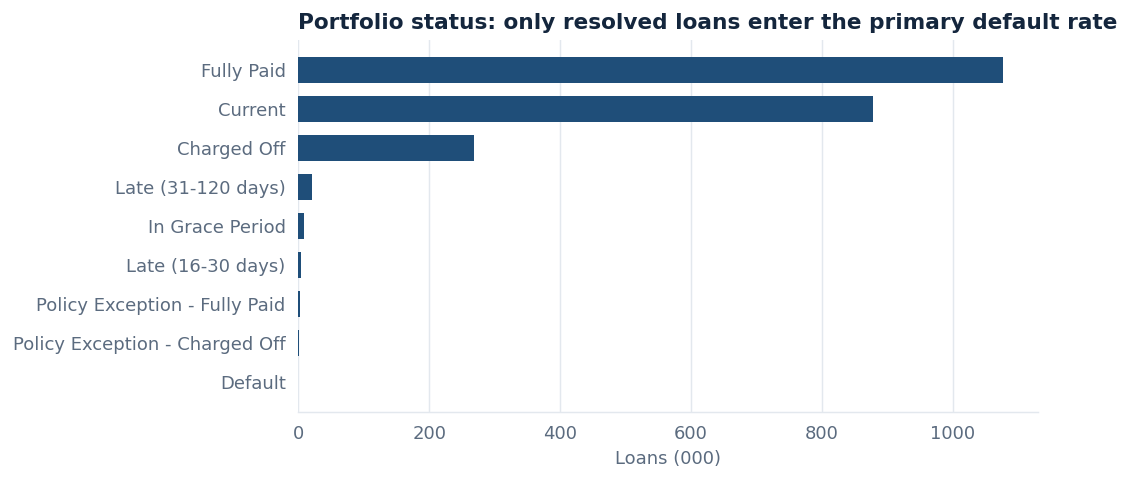

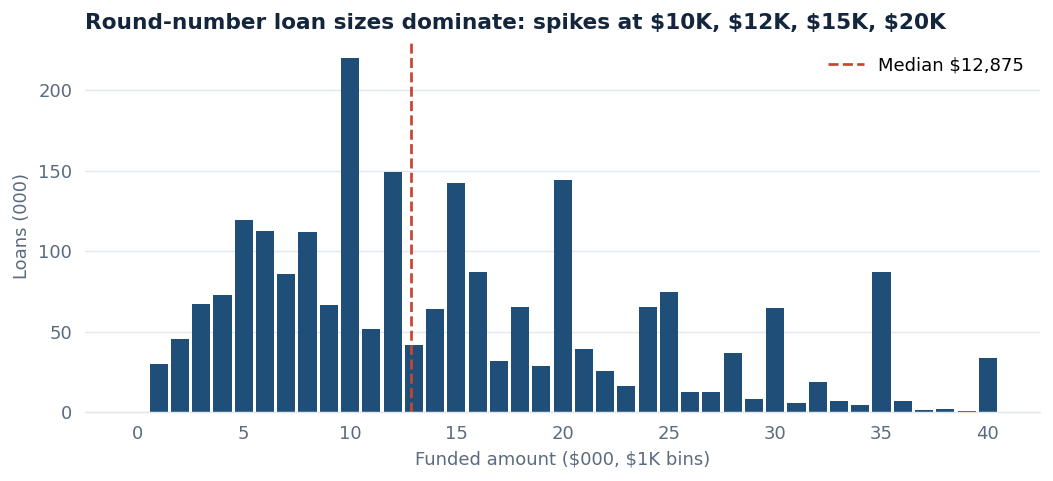

In [3]:
show('a_status_distribution'); show('a_loan_amount_distribution')

## Default analysis

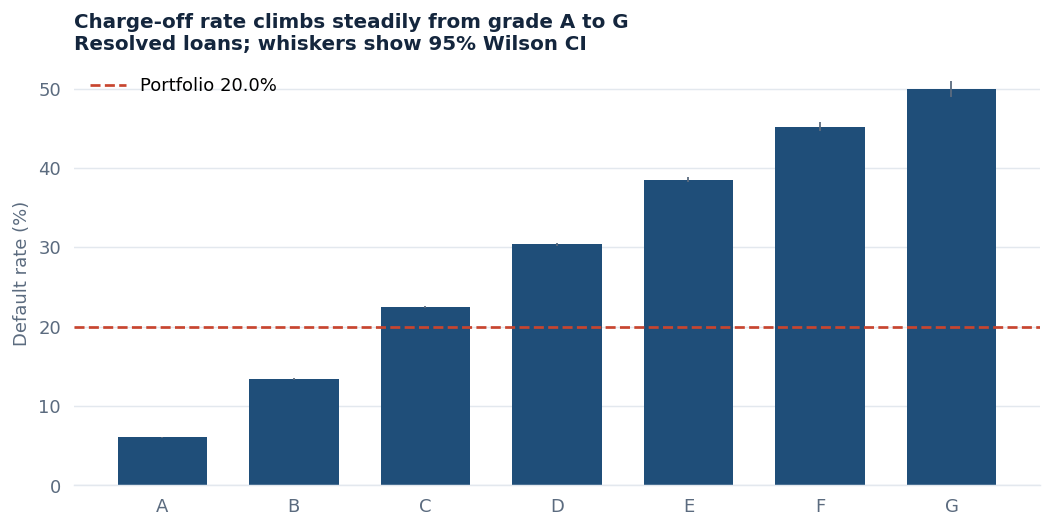

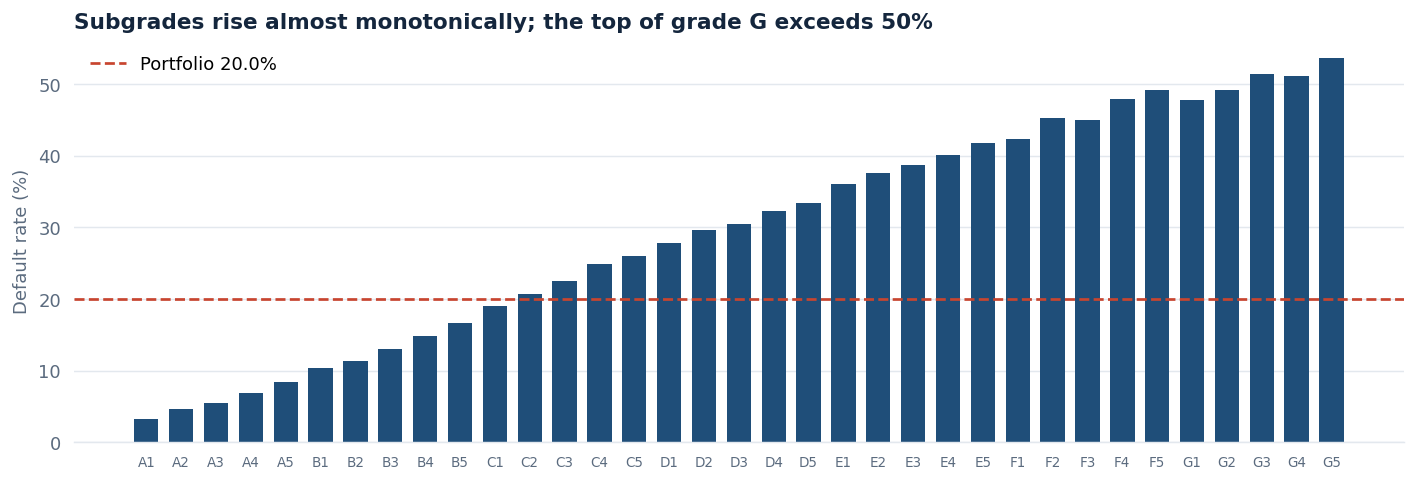

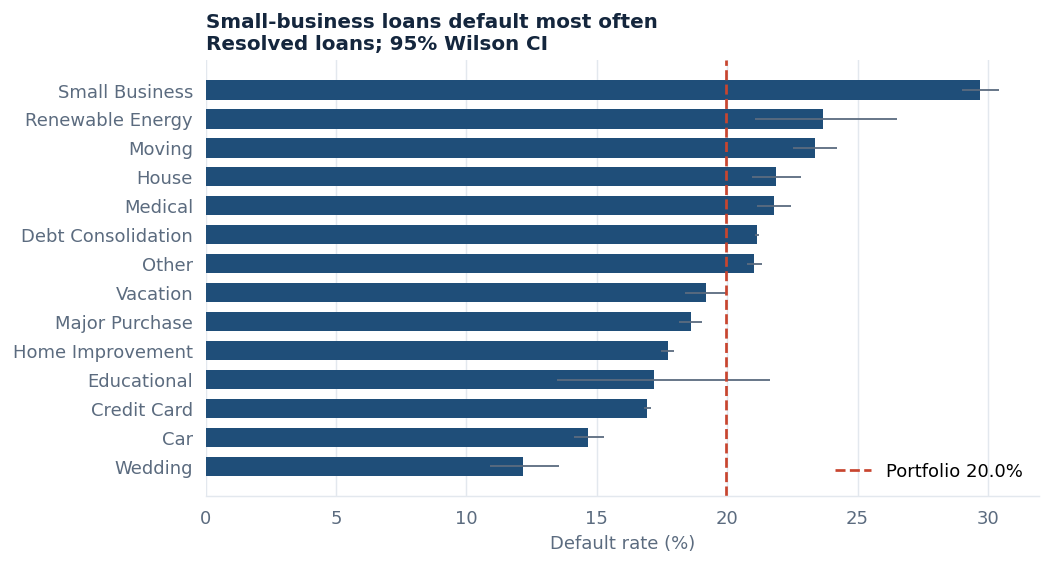

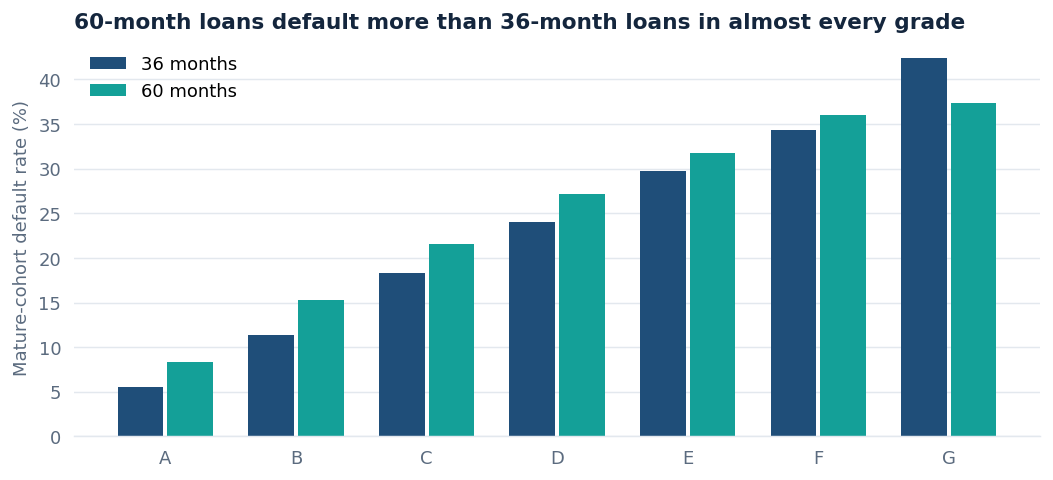

In [4]:
show('b_default_by_grade'); show('b_default_by_subgrade'); show('b_default_by_purpose'); show('b_default_by_grade_term')

## Interest rates
Pricing follows grade, so rate and default move together. That is pricing for risk rather than proof that rate alone causes default.

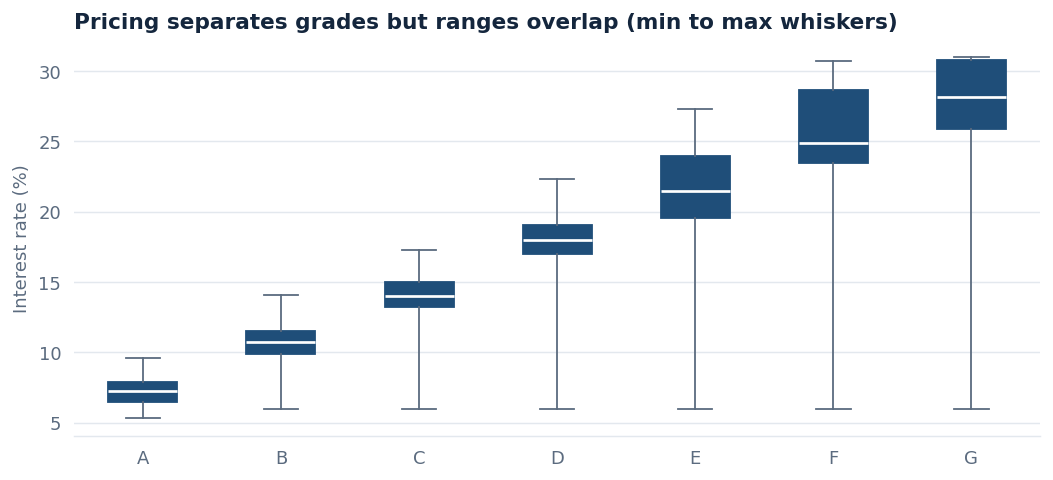

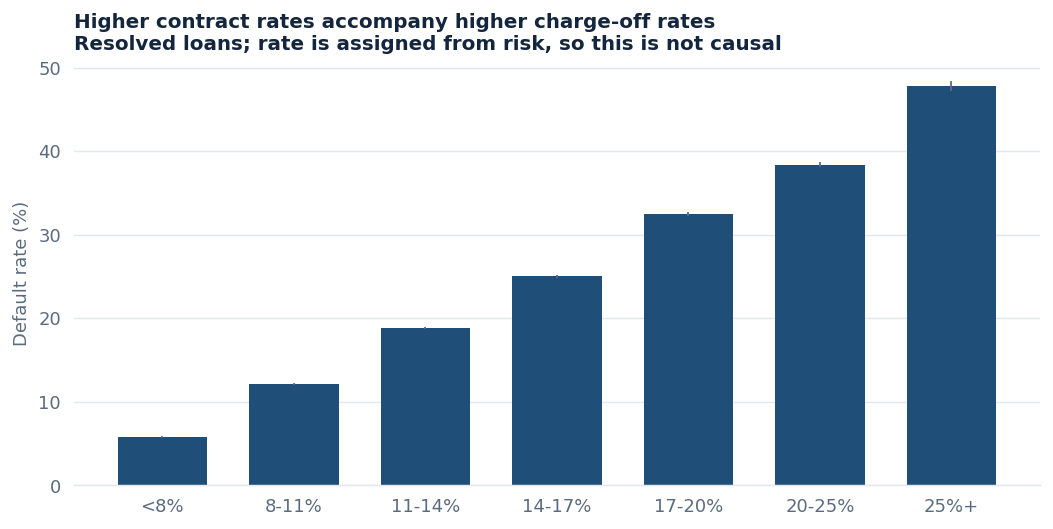

,status_clean,loans,avg_rate,median_rate
0,Default,40,16.1818,16.7300
1,Charged Off,268559,15.7107,15.0500
2,Late (31-120 days),21467,15.6372,14.9900
3,In Grace Period,8436,15.4612,14.9900
4,Late (16-30 days),4349,15.4114,14.5200
5,Policy Exception - Charged Off,761,14.5971,14.5000
6,Policy Exception - Fully Paid,1988,13.9786,13.9800
7,Current,878317,12.7681,11.9900
8,Fully Paid,1076751,12.6233,12.2300


In [5]:
show('d_rate_by_grade'); show('d_default_by_rate_band'); csv('interest_rate_by_status')

## Time
Only cohorts whose terms have elapsed compare fairly. The resolved-only rate for 2016 and 2017 is inflated because early failures resolve first.

In [6]:
csv('summary_issue_year')[['issue_year','loans','default_rate','mature_default_rate','pct_term_elapsed','unresolved_share']]

,issue_year,loans,default_rate,mature_default_rate,pct_term_elapsed,unresolved_share
0,2007,603,0.1793,0.1793,1.0000,0.0000
1,2008,2393,0.1581,0.1581,1.0000,0.0000
2,2009,5281,0.1260,0.1260,1.0000,0.0000
3,2010,12537,0.1289,0.1289,1.0000,0.0000
4,2011,21721,0.1518,0.1518,1.0000,0.0000
5,2012,53367,0.1620,0.1620,1.0000,0.0000
6,2013,134814,0.1560,0.1560,1.0000,0.0001
7,2014,235629,0.1845,0.1463,0.7465,0.0532
8,2015,421095,0.2018,0.1489,0.6725,0.1082
9,2016,434407,0.2328,0.1610,0.2213,0.3253


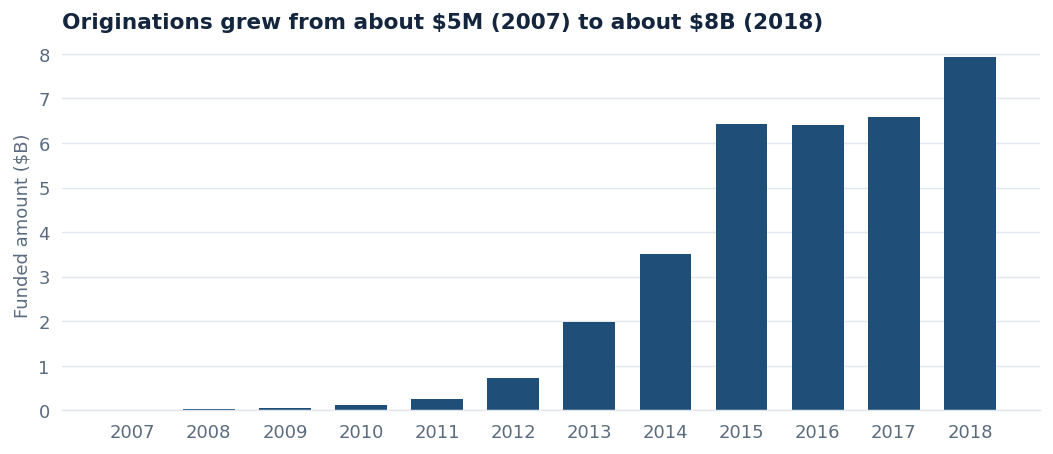

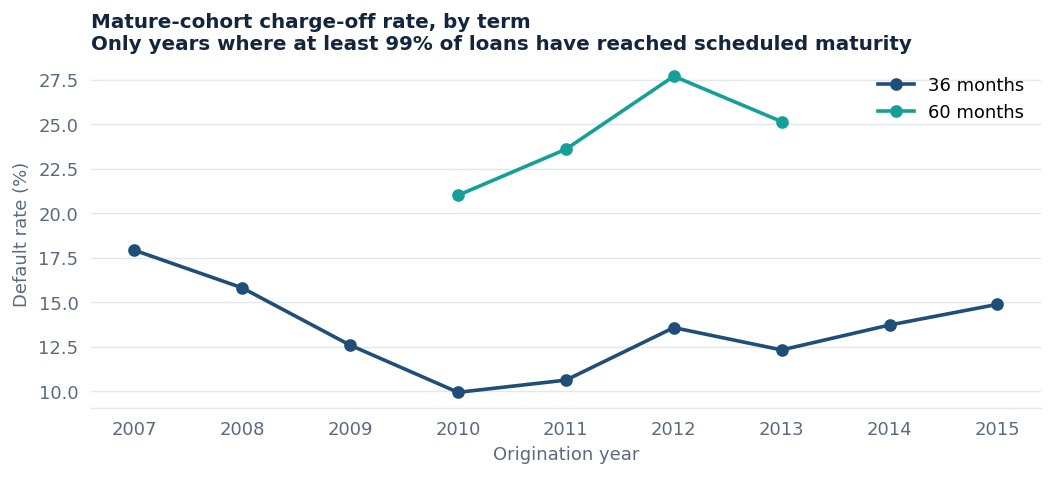

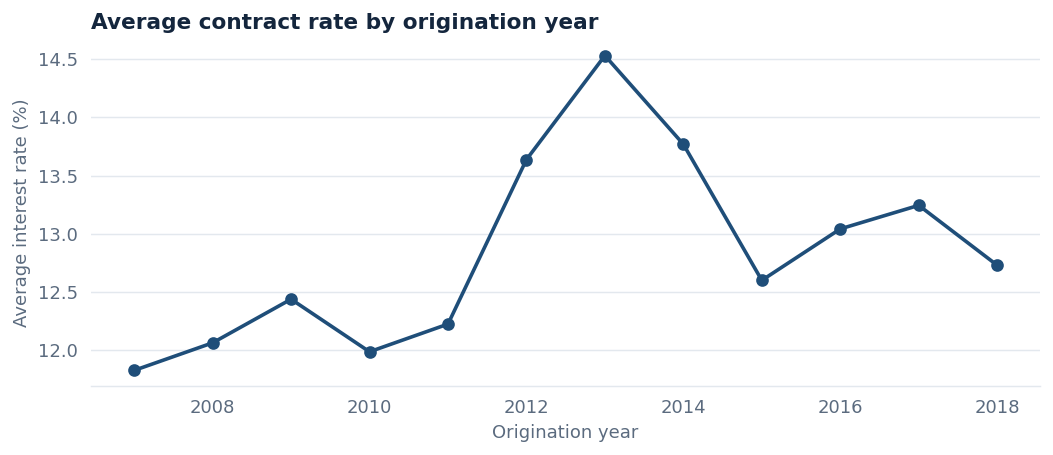

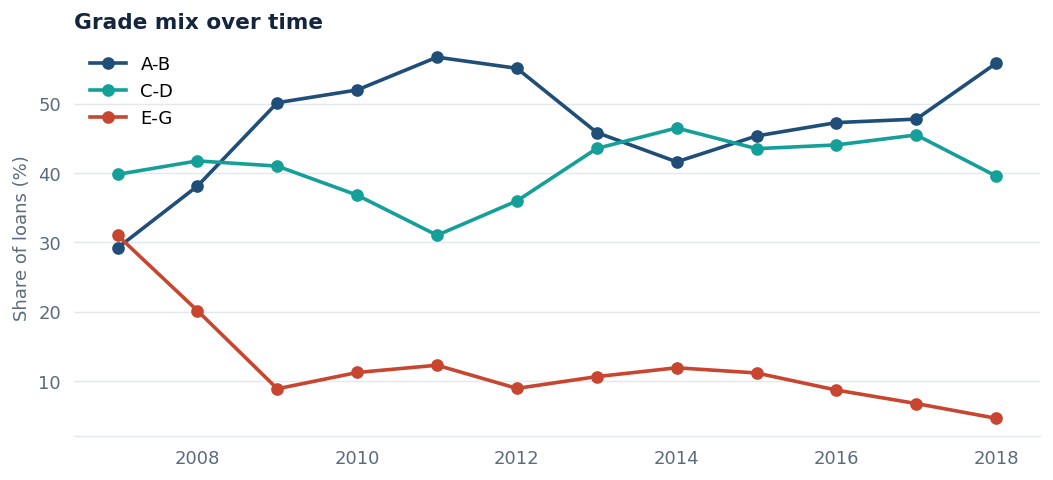

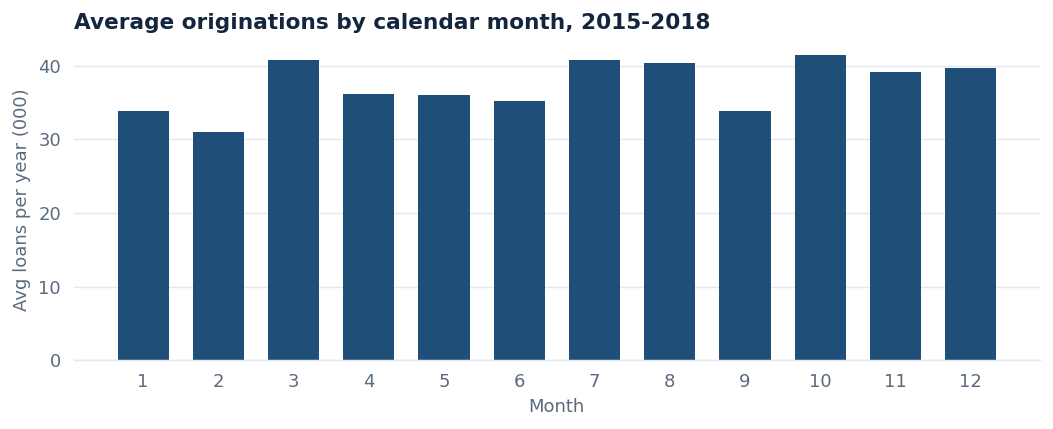

In [7]:
show('f_originations_by_year'); show('f_mature_cohort_default'); show('f_avg_rate_by_year'); show('f_grade_mix'); show('f_originations_by_month')

## Geography
Descriptive only; these rates do not establish that location causes default.

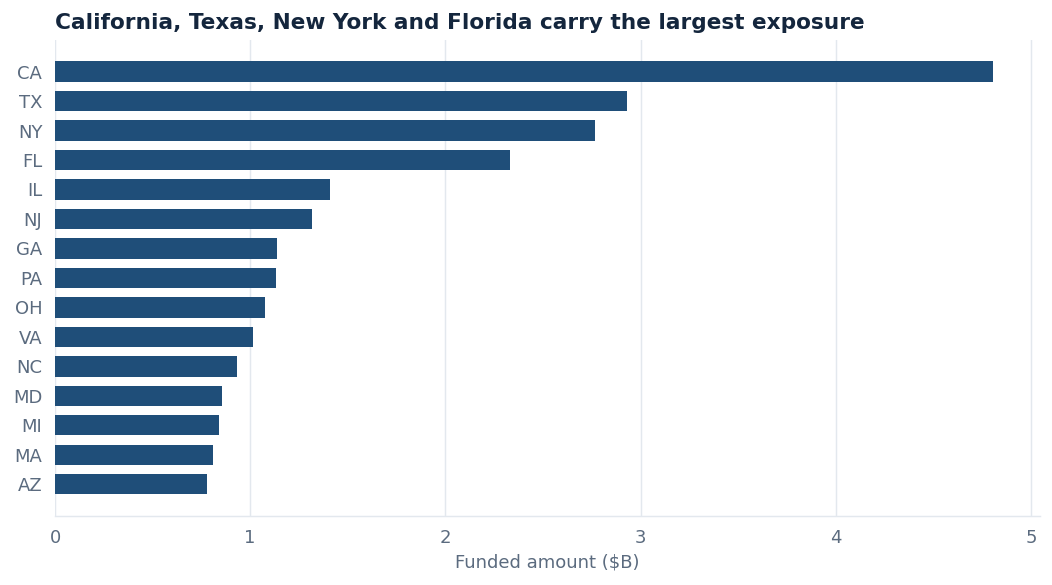

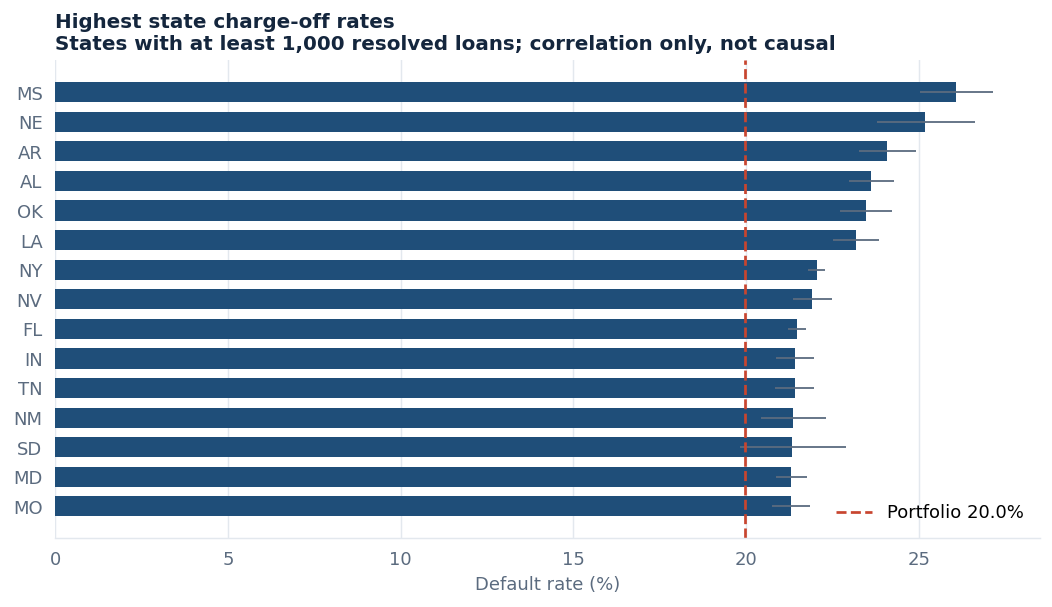

In [8]:
show('g_funded_by_state'); show('g_default_by_state_top')